# NTK Weights for the PINN Boundary Loss

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/01-pinns/ntk-boundary-weights.ipynb)

A PINN for the Poisson problem

$$
u''(x) = -\pi^2\sin(\pi x), \quad 0<x<1, \qquad u(0)=u(1)=0,
$$

has the exact solution $u=\sin(\pi x)$.
The network $\hat{u}(x)$ makes two kinds of error.
The boundary errors are $\mathbf{e}_b = \big(\hat{u}(0), \hat{u}(1)\big)$, and the PDE residuals at the collocation points $x_j$ are $e_{r,j} = \hat{u}''(x_j) + \pi^2\sin(\pi x_j)$.
The loss weights the two kinds of error,

$$
L(\theta) = \frac{w_b}{2}\|\mathbf{e}_b\|^2 + \frac{w_r}{2}\|\mathbf{e}_r\|^2 .
$$

Equal weights $w_b = w_r = 1$ give the two terms equal coefficients in the loss.
Do they also make the two errors decrease at the same rate?

## The error dynamics

Stack the errors as $\mathbf{e} = (\mathbf{e}_b, \mathbf{e}_r)$, write $J = \partial\mathbf{e}/\partial\theta$ for their Jacobian, and put the weights on the diagonal of $W$.
Gradient flow moves the parameters by $d\theta/ds = -\nabla_\theta L = -J^\top W\mathbf{e}$, where $s$ is training time.
By the chain rule the errors move by $d\mathbf{e}/ds = J\,d\theta/ds$, so

$$
\frac{d}{ds}\begin{pmatrix}\mathbf{e}_b\\ \mathbf{e}_r\end{pmatrix}
= -\underbrace{\begin{pmatrix}K_{bb} & K_{br}\\ K_{rb} & K_{rr}\end{pmatrix}}_{K = JJ^\top}
\underbrace{\begin{pmatrix}w_b I & 0\\ 0 & w_r I\end{pmatrix}}_{W}
\begin{pmatrix}\mathbf{e}_b\\ \mathbf{e}_r\end{pmatrix}.
$$

The matrix $K$ is the neural tangent kernel (NTK) of the PINN.
Its entry $K_{ij} = \nabla_\theta e_i^\top\nabla_\theta e_j$ measures how much a parameter update that reduces error $j$ also changes error $i$.
The weights multiply the errors, and the kernel sets how fast a parameter update can change them.
While $K$ stays constant, the scaled errors $W^{1/2}\mathbf{e}$ decay along the eigenvectors of $W^{1/2}KW^{1/2}$, each at a rate equal to its eigenvalue.
Equal weights give equal rates only when the boundary block $K_{bb}$ and the PDE block $K_{rr}$ have eigenvalues of similar size.

## The NTK weights

Wang, Yu and Perdikaris (2022) choose the weights from the traces of the kernel blocks,

$$
w_b = \frac{\operatorname{tr}K}{\operatorname{tr}K_{bb}}, \qquad
w_r = \frac{\operatorname{tr}K}{\operatorname{tr}K_{rr}}, \qquad
\operatorname{tr}K = \operatorname{tr}K_{bb} + \operatorname{tr}K_{rr}.
$$

With these weights $w_b\operatorname{tr}K_{bb} = w_r\operatorname{tr}K_{rr} = \operatorname{tr}K$, so the two diagonal blocks of $W^{1/2}KW^{1/2}$ have the same trace.
When the cross blocks are zero, the trace of a block is the sum of the decay rates of its errors, and the boundary errors and the PDE residuals get the same total rate.
Each diagonal entry $K_{ii} = \|\nabla_\theta e_i\|^2$ is a squared gradient norm, so the weights need one gradient per training point and never the full kernel.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def ntk_weights(K, nb):
    """NTK weights w_b = tr K / tr K_bb and w_r = tr K / tr K_rr. The first nb rows of K are boundary errors."""
    tr_bb, tr_rr = np.trace(K[:nb, :nb]), np.trace(K[nb:, nb:])
    return (tr_bb + tr_rr) / tr_bb, (tr_bb + tr_rr) / tr_rr

def weight_vector(n, nb, w_b, w_r):
    """Diagonal of W for nb boundary errors followed by n - nb PDE residuals."""
    return np.r_[np.full(nb, w_b), np.full(n - nb, w_r)]

def rates(K, w):
    """Eigenvalues of W^(1/2) K W^(1/2), the decay rates of the scaled errors."""
    sq = np.sqrt(w)
    return np.linalg.eigvalsh(sq[:, None] * K * sq[None, :])

## A model with three parameters

The model $\hat{u}(x) = a + bx + c\sin(\pi x)$ is linear in $\theta = (a,b,c)$, so its kernel stays constant for the whole of training.
It trains on the two boundary points and on the PDE residual at $x = 1/2$.
The errors are $e_{b,0} = a$, $e_{b,1} = a+b$, and $e_r = \pi^2(1-c)$, with gradients $(1,0,0)$, $(1,1,0)$, and $(0,0,-\pi^2)$.
The kernel is

$$
K = \begin{pmatrix}1&1&0\\1&2&0\\0&0&\pi^4\end{pmatrix}.
$$

The boundary block has eigenvalues $(3\mp\sqrt5)/2 \approx 0.382$ and $2.618$, and the PDE block is $\pi^4 \approx 97.409$.
The cross blocks are zero because the line $a + bx$ has zero second derivative and $\sin(\pi x)$ vanishes at both ends.
The PDE residual sets $c$ alone, and only the boundary errors can set $a$ and $b$.

In [2]:
# Rows of J are the gradients of e_b(0) = a, e_b(1) = a + b, and e_r(1/2) = pi^2 (1 - c).
J_toy = np.array([[1.0, 0.0, 0.0],
                  [1.0, 1.0, 0.0],
                  [0.0, 0.0, -np.pi**2]])
K_toy = J_toy @ J_toy.T
print("K =\n", np.round(K_toy, 3))

toy_weights = {"equal weights": (1.0, 1.0), "NTK weights": ntk_weights(K_toy, 2)}
print(f"\n{'':14s} {'w_b':>7s} {'w_r':>7s}   boundary rates   PDE rate")
for name, (w_b, w_r) in toy_weights.items():
    # The blocks are uncoupled, so each block's rates are its weight times its eigenvalues.
    rb = w_b * np.linalg.eigvalsh(K_toy[:2, :2])
    rr = w_r * K_toy[2, 2]
    print(f"{name:14s} {w_b:7.3f} {w_r:7.4f}   {rb[0]:6.3f} {rb[1]:7.3f}   {rr:8.3f}")

K =
 [[ 1.     1.     0.   ]
 [ 1.     2.     0.   ]
 [ 0.     0.    97.409]]

                   w_b     w_r   boundary rates   PDE rate
equal weights    1.000  1.0000    0.382   2.618     97.409
NTK weights     33.470  1.0308   12.784  87.625    100.409


The NTK weights are $w_b = 100.409/3 = 33.470$ and $w_r = 100.409/97.409 = 1.031$.
They raise the two boundary rates by a factor of 33.47, to 12.784 and 87.625, and they raise the PDE rate from 97.409 to 100.409.

Gradient descent takes the steps $\theta \leftarrow \theta - \eta J^\top W\mathbf{e}$.
A larger weight raises the largest eigenvalue $\lambda_{\max}$ of $W^{1/2}KW^{1/2}$, and the step must stay below $2/\lambda_{\max}$ for gradient descent to be stable.
Each run therefore uses $\eta = 1/(2\lambda_{\max})$ for its own weights, so the two runs take steps of the same size relative to their stability limits.
Both runs start from $(a,b,c) = (0.8,-0.3,0)$, and the plots show the two unweighted loss terms $\tfrac12\|\mathbf{e}_b\|^2$ and $\tfrac12\|\mathbf{e}_r\|^2$.

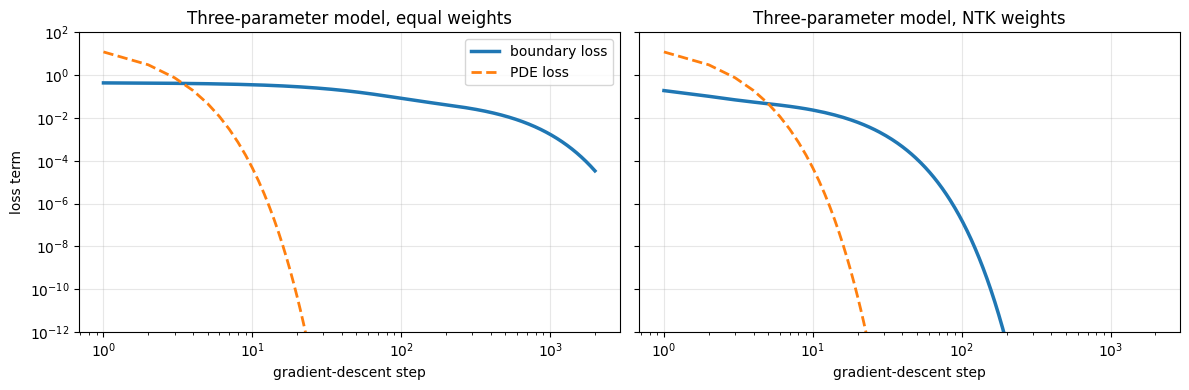

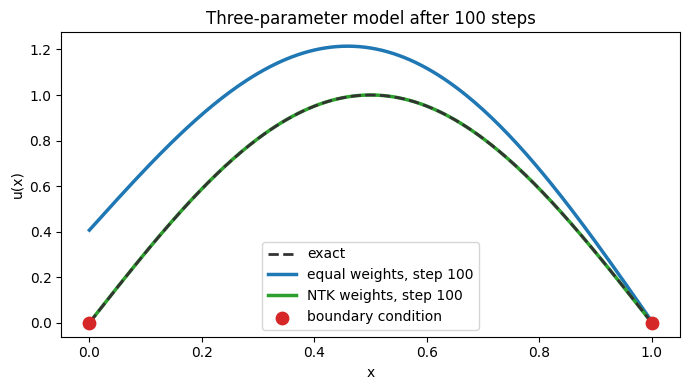

equal weights
  step   10   boundary loss 3.6e-01   PDE loss 4.6e-05   (a, b, c) = (+0.737, -0.324, 0.999)
  step   20   boundary loss 2.9e-01   PDE loss 4.4e-11   (a, b, c) = (+0.681, -0.343, 1.000)
  step  100   boundary loss 8.3e-02   PDE loss 0.0e+00   (a, b, c) = (+0.407, -0.401, 1.000)
  step 1000   boundary loss 1.7e-03   PDE loss 0.0e+00   (a, b, c) = (+0.050, -0.081, 1.000)
NTK weights
  step   10   boundary loss 2.3e-02   PDE loss 4.6e-05   (a, b, c) = (+0.185, -0.297, 0.999)
  step   20   boundary loss 6.3e-03   PDE loss 4.4e-11   (a, b, c) = (+0.095, -0.154, 1.000)
  step  100   boundary loss 1.7e-07   PDE loss 0.0e+00   (a, b, c) = (+0.000, -0.001, 1.000)
  step 1000   boundary loss 6.4e-59   PDE loss 0.0e+00   (a, b, c) = (+0.000, -0.000, 1.000)


In [3]:
def toy_errors(theta):
    a, b, c = theta
    return np.array([a, a + b, np.pi**2 * (1 - c)])

def train_toy(w_b, w_r, steps=2000, theta0=(0.8, -0.3, 0.0)):
    w = weight_vector(3, 2, w_b, w_r)
    eta = 0.5 / rates(K_toy, w).max()
    theta, history = np.array(theta0), []
    for k in range(steps + 1):
        e = toy_errors(theta)
        history.append((theta.copy(), 0.5 * e[:2] @ e[:2], 0.5 * e[2]**2))
        theta = theta - eta * J_toy.T @ (w * e)   # gradient step on the weighted loss
    return history

toy_runs = {name: train_toy(*w) for name, w in toy_weights.items()}

steps = np.arange(1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, history) in zip(axes, toy_runs.items()):
    ax.loglog(steps, [history[k][1] for k in steps], color="tab:blue", lw=2.5, label="boundary loss")
    ax.loglog(steps, [max(history[k][2], 1e-300) for k in steps], "--", color="tab:orange", lw=2, label="PDE loss")
    ax.set(title=f"Three-parameter model, {name}", xlabel="gradient-descent step", ylim=(1e-12, 1e2))
    ax.grid(True, which="major", alpha=0.3)
axes[0].set_ylabel("loss term")
axes[0].legend()
plt.tight_layout()
plt.show()

x = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, np.sin(np.pi * x), "--", color="#333333", lw=2, zorder=5, label="exact")
for (name, history), color in zip(toy_runs.items(), ["tab:blue", "tab:green"]):
    a, b, c = history[100][0]
    ax.plot(x, a + b * x + c * np.sin(np.pi * x), color=color, lw=2.5, label=f"{name}, step 100")
ax.scatter([0, 1], [0, 0], color="tab:red", s=80, zorder=6, label="boundary condition")
ax.set(xlabel="x", ylabel="u(x)", title="Three-parameter model after 100 steps")
ax.legend()
plt.tight_layout()
plt.show()

for name, history in toy_runs.items():
    print(name)
    for k in (10, 20, 100, 1000):
        theta, L_b, L_r = history[k]
        print(f"  step {k:4d}   boundary loss {L_b:.1e}   PDE loss {L_r:.1e}   "
              f"(a, b, c) = ({theta[0]:+.3f}, {theta[1]:+.3f}, {theta[2]:.3f})")

The PDE mode has the largest rate in both runs, so $\eta\lambda_{\max} = 1/2$ halves the PDE residual at every step.
The coefficient $c$ reaches 1 within 20 steps, and the PDE loss is $4\times10^{-11}$ at step 20 with either weighting.
With equal weights the slowest boundary mode shrinks by the factor $1 - 0.382/(2\times 97.409) = 0.998$ per step, which takes 510 steps to reduce its error by a factor of $e$.
At step 100 the solution is $\sin(\pi x) + 0.407 - 0.401x$, the correct curvature on a tilted line, and the boundary loss is $8.3\times10^{-2}$.
With the NTK weights the factor is $1 - 12.784/(2\times 100.409) = 0.936$, which takes 15 steps per factor of $e$, and the boundary loss at step 100 is $1.7\times10^{-7}$.

## A tanh network

The three-parameter model has no cross blocks.
A neural network couples the boundary values to the interior, because the same parameters set both.
The network here has one hidden layer of $m = 512$ tanh units,

$$
\hat{u}(x) = \frac{1}{\sqrt m}\sum_{i=1}^m a_i\tanh(w_ix+b_i), \qquad \theta = (a,w,b)\in\mathbb{R}^{3m},
$$

with $a_i\sim\mathcal{N}(0,1)$, $w_i\sim\mathcal{N}(0,4^2)$, and $b_i\sim\mathcal{N}(0,2^2)$.
The factor $1/\sqrt m$ keeps the kernel of order one as the width grows.
With $h_i = \tanh(w_ix+b_i)$ and $s_i = 1-h_i^2$, the second derivative of the output is

$$
\hat{u}''(x) = \frac{1}{\sqrt m}\sum_{i=1}^m a_iw_i^2h_i'', \qquad h'' = -2hs, \qquad h''' = (-2+6h^2)s .
$$

The code differentiates $\hat{u}$ and $\hat{u}''$ by hand with respect to $a$, $w$, and $b$ to build $J_b$ and $J_r$, and it checks both Jacobians against finite differences.
Training uses the two boundary points and 30 collocation points at the midpoints of 30 equal cells.
The model is $\hat{u}(x) - \hat{u}_0(x)$, the network minus its output $\hat{u}_0$ at the initial parameters $\theta_0$.
Subtracting the initial output leaves the Jacobian unchanged, so training starts from the zero function with the same kernel.

In [4]:
def init_params(m, sw=4.0, sb=2.0, seed=0):
    rng = np.random.default_rng(seed)
    return np.concatenate([rng.normal(0, 1, m), rng.normal(0, sw, m), rng.normal(0, sb, m)])

def split(theta):
    m = len(theta) // 3
    return theta[:m], theta[m:2*m], theta[2*m:], m

def u_and_jac(theta, x):
    """Network output u(x) and its Jacobian rows du/dtheta, one row per input."""
    a, w, b, m = split(theta)
    x = np.asarray(x, float)[:, None]
    h = np.tanh(x * w + b); s = 1 - h * h; c = 1 / np.sqrt(m)
    return (h @ a) * c, np.hstack([h * c, a * s * x * c, a * s * c])

def uxx_and_jac(theta, x):
    """Second input derivative u''(x) and its Jacobian rows du''/dtheta."""
    a, w, b, m = split(theta)
    x = np.asarray(x, float)[:, None]
    h = np.tanh(x * w + b); s = 1 - h * h
    h2 = -2 * h * s; h3 = (-2 + 6 * h * h) * s; c = 1 / np.sqrt(m)
    return (h2 * w * w) @ a * c, np.hstack([w * w * h2 * c, a * (2 * w * h2 + w * w * h3 * x) * c, a * w * w * h3 * c])

def fd_jacobian(fun, theta, x, eps=1e-6):
    cols = []
    for p in range(len(theta)):
        d = np.zeros_like(theta); d[p] = eps
        cols.append((fun(theta + d, x)[0] - fun(theta - d, x)[0]) / (2 * eps))
    return np.stack(cols, axis=1)

theta_small, x_check = init_params(16, seed=3), np.linspace(-0.9, 0.9, 7)
assert np.allclose(u_and_jac(theta_small, x_check)[1], fd_jacobian(u_and_jac, theta_small, x_check), atol=1e-7)
assert np.allclose(uxx_and_jac(theta_small, x_check)[1], fd_jacobian(uxx_and_jac, theta_small, x_check), atol=1e-6)
print("Both Jacobians match finite differences.")

xb = np.array([0.0, 1.0])
xr = (np.arange(30) + 0.5) / 30
nb = len(xb)
u_exact = lambda x: np.sin(np.pi * x)
forcing = lambda x: -np.pi**2 * np.sin(np.pi * x)

theta0 = init_params(512, seed=7)
ub0, ur0 = u_and_jac(theta0, xb)[0], uxx_and_jac(theta0, xr)[0]

def pinn_errors(theta):
    """Boundary errors then PDE residuals of u(x; theta) - u(x; theta0), and their Jacobian."""
    ub, Jb = u_and_jac(theta, xb)
    ur, Jr = uxx_and_jac(theta, xr)
    e = np.r_[(ub - ub0) - u_exact(xb), (ur - ur0) - forcing(xr)]
    return e, np.vstack([Jb, Jr])

e0, J0 = pinn_errors(theta0)
K0 = J0 @ J0.T
w_b0, w_r0 = ntk_weights(K0, nb)
print(f"tr K_bb = {np.trace(K0[:nb, :nb]):.3f}   tr K_rr = {np.trace(K0[nb:, nb:]):,.0f}   "
      f"ratio = {np.trace(K0[nb:, nb:]) / np.trace(K0[:nb, :nb]):,.0f}")
print(f"largest |K_br| entry = {np.abs(K0[:nb, nb:]).max():.2f}")
print(f"NTK weights at initialization: w_b = {w_b0:.1f}   w_r = {w_r0:.4f}")

Both Jacobians match finite differences.
tr K_bb = 1.947   tr K_rr = 4,778   ratio = 2,454
largest |K_br| entry = 5.10
NTK weights at initialization: w_b = 2455.0   w_r = 1.0004


The PDE block has trace 4,778 and the boundary block has trace 1.947, a ratio of 2,454.
Each term of $\hat{u}''$ carries the factor $w_i^2$, and with $w_i\sim\mathcal{N}(0,4^2)$ the residual gradients are much larger than the boundary gradients.
The NTK weights at initialization are $w_b = 2455.0$ and $w_r = 1.0004$.
The cross block is nonzero, with entries up to 5.10, so every step that reduces the PDE residual also moves the boundary values.

Both runs below train the full network with gradient descent for 20,000 steps.
Every 100 steps they recompute the kernel and the step $\eta = 1/(2\lambda_{\max})$, and the NTK run also recomputes its weights from the current kernel.

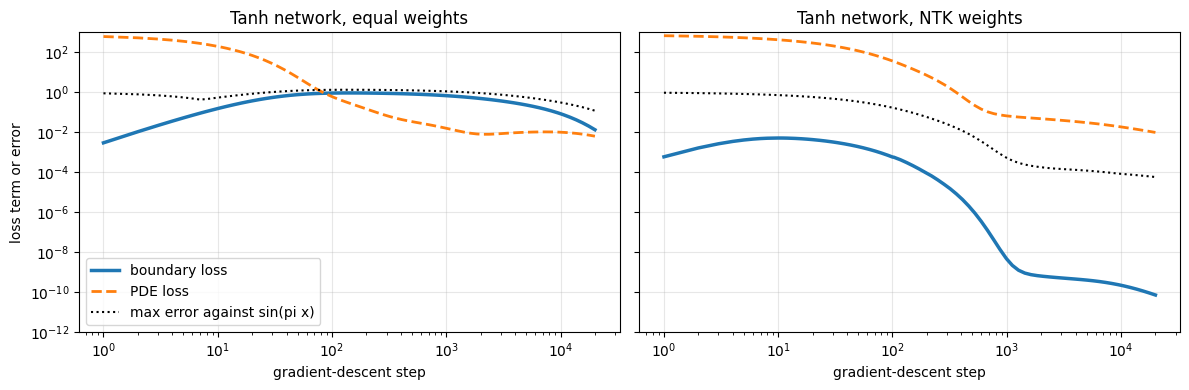

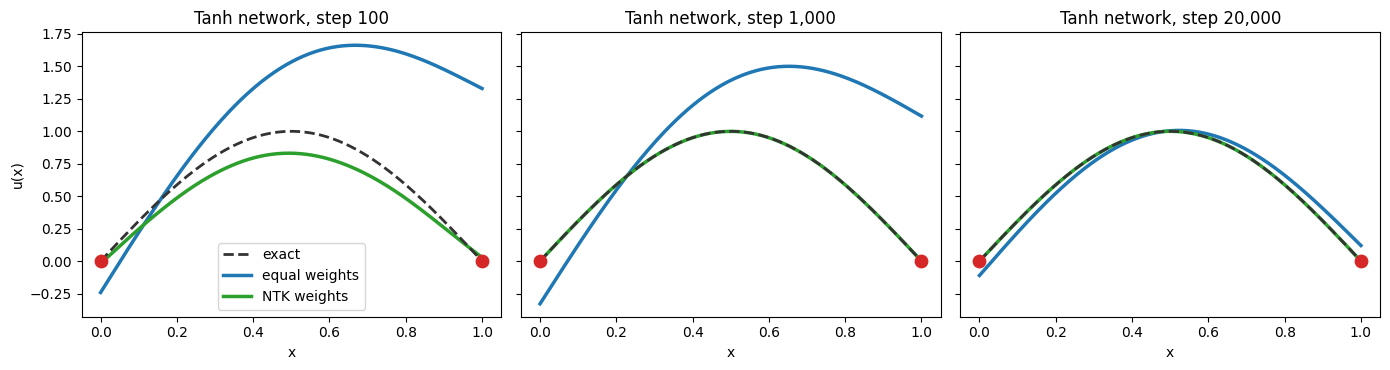

equal weights
  step      0   boundary loss 7.5e-33   PDE loss 7.3e+02   max error 1.0e+00   w_b 1.0
  step     10   boundary loss 1.5e-01   PDE loss 2.0e+02   max error 5.4e-01   w_b 1.0
  step    100   boundary loss 9.1e-01   PDE loss 6.1e-01   max error 1.3e+00   w_b 1.0
  step  1,000   boundary loss 6.8e-01   PDE loss 1.6e-02   max error 1.1e+00   w_b 1.0
  step 10,000   boundary loss 8.4e-02   PDE loss 1.0e-02   max error 3.1e-01   w_b 1.0
  step 20,000   boundary loss 1.3e-02   PDE loss 6.4e-03   max error 1.2e-01   w_b 1.0
NTK weights
  step      0   boundary loss 7.5e-33   PDE loss 7.3e+02   max error 1.0e+00   w_b 2455.0
  step     10   boundary loss 5.2e-03   PDE loss 4.2e+02   max error 7.2e-01   w_b 2455.0
  step    100   boundary loss 5.8e-04   PDE loss 3.7e+01   max error 1.7e-01   w_b 2372.0
  step  1,000   boundary loss 4.5e-09   PDE loss 6.6e-02   max error 5.2e-04   w_b 2298.9
  step 10,000   boundary loss 2.2e-10   PDE loss 1.9e-02   max error 8.3e-05   w_b 2298.3
  

In [5]:
xt = np.linspace(0, 1, 201)
ut0 = u_and_jac(theta0, xt)[0]
log_steps = set(np.unique(np.round(np.logspace(0, np.log10(20_000), 80)).astype(int))) | {0, 100, 1_000, 10_000, 20_000}

def train_pinn(use_ntk_weights, steps=20_000, every=100):
    theta, log, snapshots = theta0.copy(), [], {}
    for k in range(steps + 1):
        e, J = pinn_errors(theta)
        if k % every == 0:
            K = J @ J.T
            w_b, w_r = ntk_weights(K, nb) if use_ntk_weights else (1.0, 1.0)
            w = weight_vector(len(e), nb, w_b, w_r)
            eta = 0.5 / rates(K, w).max()
        if k in log_steps:
            u_now = u_and_jac(theta, xt)[0] - ut0
            log.append((k, 0.5 * e[:nb] @ e[:nb], 0.5 * e[nb:] @ e[nb:], np.abs(u_now - u_exact(xt)).max(), w_b))
            snapshots[k] = u_now
        theta = theta - eta * J.T @ (w * e)   # gradient step on the weighted loss
    return np.array(log), snapshots

pinn_runs = {name: train_pinn(name == "NTK weights") for name in ["equal weights", "NTK weights"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, (log, _)) in zip(axes, pinn_runs.items()):
    log = log[log[:, 0] > 0]   # a log axis has no step 0
    ax.loglog(log[:, 0], log[:, 1], color="tab:blue", lw=2.5, label="boundary loss")
    ax.loglog(log[:, 0], log[:, 2], "--", color="tab:orange", lw=2, label="PDE loss")
    ax.loglog(log[:, 0], log[:, 3], ":", color="k", lw=1.5, label="max error against sin(pi x)")
    ax.set(title=f"Tanh network, {name}", xlabel="gradient-descent step", ylim=(1e-12, 1e3))
    ax.grid(True, which="major", alpha=0.3)
axes[0].set_ylabel("loss term or error")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, k in zip(axes, (100, 1_000, 20_000)):
    ax.plot(xt, u_exact(xt), "--", color="#333333", lw=2, zorder=5, label="exact")
    for (name, (_, snapshots)), color in zip(pinn_runs.items(), ["tab:blue", "tab:green"]):
        ax.plot(xt, snapshots[k], color=color, lw=2.5, label=name)
    ax.scatter([0, 1], [0, 0], color="tab:red", s=80, zorder=6)
    ax.set(xlabel="x", title=f"Tanh network, step {k:,}")
axes[0].set_ylabel("u(x)")
axes[0].legend()
plt.tight_layout()
plt.show()

for name, (log, _) in pinn_runs.items():
    print(name)
    for k in (0, 10, 100, 1_000, 10_000, 20_000):
        row = log[log[:, 0] == k][0]
        print(f"  step {k:6,d}   boundary loss {row[1]:.1e}   PDE loss {row[2]:.1e}   "
              f"max error {row[3]:.1e}   w_b {row[4]:.1f}")

With equal weights the boundary loss starts at zero and rises to 0.91 by step 100.
The PDE loss falls from $7.3\times10^{2}$ to 0.61 over the same steps, and the cross block drags the boundary values away from zero.
The equal-weight network then looks like the correct curve on a tilted line, as in the three-parameter model, and its boundary loss is still $1.3\times10^{-2}$ after 20,000 steps.
With the NTK weights the boundary loss is $5.8\times10^{-4}$ at step 100 and $4.5\times10^{-9}$ at step 1,000.
The largest error against $\sin(\pi x)$ is $5.8\times10^{-5}$ at step 20,000, against 0.12 with equal weights.
The NTK run has the larger PDE loss at steps 100, 1,000, 10,000, and 20,000, with $9.8\times10^{-3}$ against $6.4\times10^{-3}$ at the last, and it is still the accurate one.
A small PDE loss does not fix the solution, because adding a line $a + bx$ leaves every PDE residual unchanged, and only the boundary loss can remove that line.
The recomputed boundary weight moves from 2455.0 at initialization to 2295.5 at step 20,000.

## The solution during training

The animation steps through the two training runs at the 74 logged steps from step 0 to step 20,000.
The top row shows the network solution at each step, and the dotted line in the bottom row marks the same step on the loss curves.
With equal weights the PDE loss falls below 1 by step 100, and the curve takes the shape of $\sin(\pi x)$ on a tilted line, with $\hat{u}(0)$ below zero and $\hat{u}(1)$ above it.
The boundary loss peaks at 0.93 at step 133, and the ends then drift toward zero so slowly that the boundary loss is still $1.3\times10^{-2}$ at step 20,000.
With the NTK weights the boundary loss never exceeds $5.2\times10^{-3}$, its value at step 10, so the ends stay near zero while the interior rises to $\sin(\pi x)$.
The largest error against $\sin(\pi x)$ is $5.2\times10^{-4}$ by step 1,000.

In [6]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

frame_steps = sorted(pinn_runs["equal weights"][1])
all_u = np.concatenate([np.stack(list(snapshots.values())) for _, snapshots in pinn_runs.values()])
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), dpi=60)
panels = []
for col, ((name, (log, snapshots)), color) in enumerate(zip(pinn_runs.items(), ["tab:blue", "tab:green"])):
    ax = axes[0, col]
    ax.plot(xt, u_exact(xt), "--", color="#333333", lw=2, zorder=5, label="exact")
    line, = ax.plot([], [], color=color, lw=2.5, label=name)
    ax.scatter([0, 1], [0, 0], color="tab:red", s=80, zorder=6)
    ax.set(xlim=(0, 1), ylim=(all_u.min() - 0.1, all_u.max() + 0.1), xlabel="x", ylabel="u(x)", title=name)
    ax.legend(loc="upper left")
    text = ax.text(0.03, 0.05, "", transform=ax.transAxes)
    ax = axes[1, col]
    logged = log[log[:, 0] > 0]   # a log axis has no step 0
    ax.loglog(logged[:, 0], logged[:, 1], color="tab:blue", lw=2.5, label="boundary loss")
    ax.loglog(logged[:, 0], logged[:, 2], "--", color="tab:orange", lw=2, label="PDE loss")
    cursor = ax.axvline(1, color="0.4", ls=":")
    ax.set(xlabel="gradient-descent step", ylabel="loss term", ylim=(1e-12, 1e3))
    ax.legend(loc="lower left")
    panels.append((line, text, cursor, log, snapshots))
title = fig.suptitle("")
fig.tight_layout(rect=[0, 0, 1, 0.95])

def draw_frame(i):
    k = frame_steps[i]
    for line, text, cursor, log, snapshots in panels:
        row = log[log[:, 0] == k][0]
        line.set_data(xt, snapshots[k])
        text.set_text(f"boundary loss {row[1]:.1e}\nPDE loss {row[2]:.1e}")
        cursor.set_xdata([max(k, 1), max(k, 1)])
    title.set_text(f"Step {k:,}")

animation = FuncAnimation(fig, draw_frame, frames=len(frame_steps))
html = animation.to_jshtml(fps=8, default_mode="once")
plt.close(fig)
display(HTML(html))
print(f"{len(frame_steps)} frames from step 0 to step {frame_steps[-1]:,}")
for name, (log, _) in pinn_runs.items():
    worst = log[:, 1].argmax()
    print(f"{name}: largest boundary loss {log[worst, 1]:.1e} at step {int(log[worst, 0]):,}")

74 frames from step 0 to step 20,000
equal weights: largest boundary loss 9.3e-01 at step 133
NTK weights: largest boundary loss 5.2e-03 at step 10


## Limits of the NTK weights

The NTK weights equalize the traces of the two blocks, and the slow modes inside the PDE block stay slow.
Those modes carry the high-frequency part of the residual, so the weights do not remove spectral bias.
The rate analysis assumes gradient descent and a kernel that changes little during training.
Adam rescales the step of each parameter, so under Adam the errors no longer follow $d\mathbf{e}/ds = -KW\mathbf{e}$, and the same weights become a heuristic.
For a nonlinear PDE the residual Jacobian contains the linearization of the operator at the current solution, so $K_{rr}$ changes with $\hat{u}$ even when the network is very wide.

## Sources

1. S. Wang, X. Yu and P. Perdikaris, When and why PINNs fail to train: a neural tangent kernel perspective, Journal of Computational Physics 449 (2022) 110768. [arXiv:2007.14527](https://arxiv.org/abs/2007.14527)
2. A. Jacot, F. Gabriel and C. Hongler, Neural tangent kernel: convergence and generalization in neural networks, NeurIPS 2018. [arXiv:1806.07572](https://arxiv.org/abs/1806.07572)